# Lab 2 — Ciclo de treino, vazamento e métricas
**Individual · 1,0 ponto na AV1 · 08/10/2026 · horário da atividade no Classroom**

Leia `ENUNCIADO.pdf` antes de preencher. A base comum está incluída; não é necessário usar o banco do projeto.

O notebook executa a preparação e um teste pequeno de ambiente. Nas atividades avaliadas, complete os **TODO** e substitua as mensagens de pendência por resultados. Não há métricas pré-medidas para copiar.

Ordem: preparação → B2 → A → C → D7 → D4–D6 → avaliação final → relatório.

## 0. Ambiente e pasta
No Colab, extraia o ZIP conforme o enunciado e execute `%cd /content/classroom-lab-02` antes da próxima célula. Localmente, abra este notebook na pasta extraída. CPU é suficiente.

In [1]:
from pathlib import Path
import sys, copy, time, importlib.metadata, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))
print('Sistema:', platform.platform(), '| CPU:', platform.processor())
print('Threads do torch:', torch.get_num_threads())

Python: 3.13.2
numpy 2.2.3
pandas 2.2.3
scikit-learn 1.5.2
matplotlib 3.10.6
torch 2.14.1
Sistema: Windows-11-10.0.26300-SP0 | CPU: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
Threads do torch: 4


### Leitura e conferência da base
`carregar_base` lê o CSV com `;`, confere sua integridade e cria o alvo e os identificadores de controle. As únicas entradas permitidas estão em `FEATURES`. Não aprende média, desvio, pesos ou partições.

Ver as contagens do arquivo não é treinar um modelo. Depois da B2, o teste principal deve permanecer fora das decisões e dos experimentos de erro.

In [2]:
base = carregar_base()
print(base.head().to_string(index=False))
print('\nLinhas:', len(base), '| características:', len(FEATURES))
print('Classe positiva:', int(base.alvo.sum()), '| proporção:', base.alvo.mean())
print('Perfis distintos:', base.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo: o que faz uma atualização
O bloco a seguir usa **quatro observações artificiais com duas entradas**, apenas para conferir instalação e formas. Não usa Wine Quality, não mede generalização e não atende às partes avaliadas. Um logit é transformado em escore por sigmoide só ao obter previsões; a perda recebe o logit.

In [3]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297777175903


## B2. Separe antes de normalizar
Implemente aproximadamente 60/20/20, conservando `grupo_perfil` em uma única partição. Use uma semente declarada. Consulte `GroupShuffleSplit`; proporções de grupos não garantem as mesmas proporções de linhas.

Retorne um dicionário com `treino`, `validacao`, `teste`, cada qual contendo um DataFrame. Mostre cobertura, interseção de linhas e perfis, contagens e classes. Não use IDs como características.

**Pergunta de uso que estou assumindo:** dado um vinho tinto com as 11 medidas físico-químicas, o modelo deve ajudar a decidir se a amostra vale ser separada para a análise especial (nota >= 7). Quero estimar como o modelo se sai em perfis de medidas **que ele nunca viu**. Por isso a unidade da separação é o `grupo_perfil` e não a linha.

Estratégia: `GroupShuffleSplit` duas vezes, com semente 42.
1. Primeiro separo ~20% dos grupos para o teste (que fica guardado até o fim).
2. Depois, dos 80% que sobraram (desenvolvimento), separo 25% dos grupos para validação. 25% de 80% dá os 20% do total, e o treino fica com ~60%.

Como a API sorteia **grupos**, o número de linhas pode sair um pouco diferente de 60/20/20. Não fiquei trocando a semente para "acertar" proporção nem classe: usei 42 e só conferi depois.

In [4]:
from sklearn.model_selection import GroupShuffleSplit

def particionar_sem_vazar(df, semente=42):
    """Separa treino/validação/teste (~60/20/20) mantendo cada grupo_perfil em um só conjunto.

    O sorteio é feito sobre grupos (perfis idênticos nas 11 medidas), sem olhar o alvo.
    Retorna um dicionário com três DataFrames.
    """
    grupos = df['grupo_perfil'].values

    # passo 1: reserva o teste
    gss_teste = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semente)
    idx_dev, idx_teste = next(gss_teste.split(df, groups=grupos))
    dev = df.iloc[idx_dev]
    teste = df.iloc[idx_teste]

    # passo 2: divide o desenvolvimento em treino e validação
    gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=semente)
    idx_tr, idx_val = next(gss_val.split(dev, groups=dev['grupo_perfil'].values))
    treino = dev.iloc[idx_tr]
    validacao = dev.iloc[idx_val]

    return {'treino': treino.reset_index(drop=True),
            'validacao': validacao.reset_index(drop=True),
            'teste': teste.reset_index(drop=True)}

particoes = particionar_sem_vazar(base, SEED)

# ---- auditoria ----
linhas_tab = []
for nome, parte in particoes.items():
    linhas_tab.append({'conjunto': nome,
                       'linhas': len(parte),
                       '% das linhas': round(100 * len(parte) / len(base), 1),
                       'positivos': int(parte.alvo.sum()),
                       'negativos': int((parte.alvo == 0).sum()),
                       'proporcao_positiva': round(parte.alvo.mean(), 4),
                       'perfis': parte.grupo_perfil.nunique()})
tabela_b2 = pd.DataFrame(linhas_tab)
print(tabela_b2.to_string(index=False))
tabela_b2.to_csv(RESULTADOS / 'b2_particoes.csv', index=False)

ids = {n: set(p.id_linha) for n, p in particoes.items()}
perfis = {n: set(p.grupo_perfil) for n, p in particoes.items()}

print('\nCobertura: soma das linhas =', sum(len(p) for p in particoes.values()), 'de', len(base))
print('Todas as linhas cobertas?', set.union(*ids.values()) == set(base.id_linha))
pares = [('treino', 'validacao'), ('treino', 'teste'), ('validacao', 'teste')]
for a, b in pares:
    print(f'{a:>9} x {b:<9} | linhas em comum: {len(ids[a] & ids[b])} | perfis em comum: {len(perfis[a] & perfis[b])}')

# checagens automáticas, para o notebook parar se algo der errado
assert set.union(*ids.values()) == set(base.id_linha)
assert all(len(ids[a] & ids[b]) == 0 and len(perfis[a] & perfis[b]) == 0 for a, b in pares)
assert all(p.alvo.nunique() == 2 for p in particoes.values())

 conjunto  linhas  % das linhas  positivos  negativos  proporcao_positiva  perfis
   treino     961          60.1        139        822              0.1446     815
validacao     318          19.9         33        285              0.1038     272
    teste     320          20.0         45        275              0.1406     272

Cobertura: soma das linhas = 1599 de 1599
Todas as linhas cobertas? True
   treino x validacao | linhas em comum: 0 | perfis em comum: 0
   treino x teste     | linhas em comum: 0 | perfis em comum: 0
validacao x teste     | linhas em comum: 0 | perfis em comum: 0


In [5]:
# Só para mostrar que índice diferente não basta: quantas linhas repetidas existem dentro de cada conjunto
for nome, parte in particoes.items():
    repetidas = parte.duplicated(subset=FEATURES).sum()
    print(f'{nome}: {repetidas} linhas que repetem um perfil já presente no próprio conjunto')

# e como seria se eu tivesse feito uma divisão aleatória simples por linha (só para comparação, não é usada)
from sklearn.model_selection import train_test_split
_dev_aleat, _teste_aleat = train_test_split(base, test_size=0.2, random_state=SEED)
vazados = _teste_aleat.grupo_perfil.isin(_dev_aleat.grupo_perfil).sum()
print(f'\nNuma divisão aleatória por linha, {vazados} linhas do teste teriam um "gêmeo" no desenvolvimento.')

treino: 146 linhas que repetem um perfil já presente no próprio conjunto
validacao: 46 linhas que repetem um perfil já presente no próprio conjunto
teste: 48 linhas que repetem um perfil já presente no próprio conjunto

Numa divisão aleatória por linha, 64 linhas do teste teriam um "gêmeo" no desenvolvimento.


**Análise B2.** A divisão ficou 961 / 318 / 320 linhas (60,1% / 19,9% / 20,0%), bem perto do 60/20/20 mesmo sorteando grupos. Todas as 1599 linhas aparecem em exatamente um conjunto e nenhum perfil das 11 medidas é compartilhado entre conjuntos, que era o objetivo.

As duas classes aparecem nos três conjuntos, mas a validação ficou com menos positivos (10,4%, só 33 linhas) do que treino (14,5%) e teste (14,1%). Não troquei a semente por causa disso, porque seria escolher partição olhando o alvo. Só registro que a escolha do limiar na D5 vai ser feita com poucos positivos, o que deixa ela mais instável.

A segunda célula mostra por que conferir só `id_linha` não basta: dentro de cada conjunto ainda existem linhas repetidas (146 no treino, por exemplo), e isso é ok porque estão do mesmo lado. Já numa divisão aleatória simples por linha, 64 linhas do teste teriam um gêmeo exato no desenvolvimento, mesmo com zero índices em comum.

Limitações: perfil igual não quer dizer vinho igual (não há identificador do vinho físico). A base também não tem data, produtor nem região, então essa partição **não** testa generalização para o futuro, para novos produtores ou para vinhos de outra origem (por exemplo, o vinho branco do mesmo estudo).

### B1. Cinco cenários
Responda no README aos cinco cenários do enunciado: avaliações de produtos; turbinas; spam; radiografias; transações. Declare o uso e as hipóteses. Na quinta resposta, discuta tempo e identidade dos clientes. As respostas não precisam de bancos adicionais.

## A1. Dataset próprio
Implemente a classe abaixo com as estatísticas opcionais. Aprenda média/desvio somente no treino e passe-os aos outros conjuntos. Trate desvio zero, preserve o alinhamento e devolva `float32`: X `[11]`, y escalar. Mostre as verificações solicitadas.

In [6]:
class MeuDataset(Dataset):
    """Dataset tabular de uma única partição do Wine Quality."""

    def __init__(self, df, features, media=None, desvio=None):
        """Prepara os tensores já normalizados.

        df: tabela de UMA partição (treino, validação ou teste).
        features: lista das 11 colunas de entrada (sem quality, alvo, ids).
        media, desvio: se None, são aprendidos com as linhas deste df (só deve
            acontecer no treino). Na validação e no teste eu passo os valores do treino.

        Convenção: desvio populacional (ddof=0, como o np.std). Se alguma coluna tiver
        desvio zero, troco por 1.0 para não dividir por zero (a coluna vira só x - média).
        """
        self.features = list(features)
        X = df[self.features].to_numpy(dtype=np.float64)

        if media is None or desvio is None:
            media = X.mean(axis=0)
            desvio = X.std(axis=0, ddof=0)
            self.estatisticas_proprias = True
        else:
            self.estatisticas_proprias = False
        media = np.asarray(media, dtype=np.float64)
        desvio = np.asarray(desvio, dtype=np.float64).copy()
        desvio[desvio == 0] = 1.0

        self.media = media
        self.desvio = desvio
        X = (X - media) / desvio

        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(df['alvo'].to_numpy(), dtype=torch.float32)
        self.ids = df['id_linha'].to_numpy()  # só para conferência, não entra no modelo

    def __len__(self):
        """Número de observações (linhas) da partição."""
        return len(self.y)

    def __getitem__(self, indice):
        """Devolve (X, y) da linha `indice`: X com forma [11] e y escalar, ambos float32."""
        return self.X[indice], self.y[indice]


ds_treino = MeuDataset(particoes['treino'], FEATURES)
ds_validacao = MeuDataset(particoes['validacao'], FEATURES, ds_treino.media, ds_treino.desvio)
ds_teste = MeuDataset(particoes['teste'], FEATURES, ds_treino.media, ds_treino.desvio)

for nome, ds in [('treino', ds_treino), ('validacao', ds_validacao), ('teste', ds_teste)]:
    x0, y0 = ds[0]
    print(f'{nome:>9}: len={len(ds):4d} | X {tuple(x0.shape)} {x0.dtype} | y {tuple(y0.shape)} {y0.dtype}'
          f' | finito? {bool(torch.isfinite(ds.X).all())} | estatística própria? {ds.estatisticas_proprias}')

# validação e teste usam exatamente o mesmo vetor de média/desvio do treino
print('\nMesma média do treino na validação e no teste?',
      np.array_equal(ds_validacao.media, ds_treino.media), np.array_equal(ds_teste.media, ds_treino.media))
print('Mesmo desvio do treino na validação e no teste?',
      np.array_equal(ds_validacao.desvio, ds_treino.desvio), np.array_equal(ds_teste.desvio, ds_treino.desvio))
print('Algum desvio zero no treino?', bool((particoes['treino'][FEATURES].std(ddof=0) == 0).any()))

# médias depois de normalizar: ~0 no treino (por construção); na validação/teste não precisa ser 0
print(pd.DataFrame({'treino': ds_treino.X.mean(0).numpy(),
                    'validacao': ds_validacao.X.mean(0).numpy(),
                    'teste': ds_teste.X.mean(0).numpy()}, index=FEATURES).round(3).to_string())

   treino: len= 961 | X (11,) torch.float32 | y () torch.float32 | finito? True | estatística própria? True
validacao: len= 318 | X (11,) torch.float32 | y () torch.float32 | finito? True | estatística própria? False
    teste: len= 320 | X (11,) torch.float32 | y () torch.float32 | finito? True | estatística própria? False

Mesma média do treino na validação e no teste? True True
Mesmo desvio do treino na validação e no teste? True True
Algum desvio zero no treino? False
                      treino  validacao  teste
fixed acidity            0.0      0.091 -0.021
volatile acidity         0.0      0.134  0.016
citric acid             -0.0      0.017 -0.009
residual sugar          -0.0     -0.009 -0.006
chlorides                0.0      0.011 -0.033
free sulfur dioxide      0.0      0.104  0.103
total sulfur dioxide     0.0      0.033  0.076
density                  0.0      0.133  0.052
pH                       0.0      0.005  0.063
sulphates               -0.0     -0.079  0.005
alcoho

## A2. Três DataLoaders
Preencha a tabela de parâmetros no README e crie os carregadores. Na avaliação não descarte observações. `obter_escores` devolve rótulos e escores percorridos juntos, evitando confundir uma ordem de rótulos com outra de previsões.

Minhas escolhas (a tabela completa está no README):

- **Treino:** `batch_size=64`, `shuffle=True`, `drop_last=False`, `num_workers=0`. O treino tem 961 linhas, então são 16 passos por época (15 lotes cheios e um último com 1 exemplo). É um meio-termo razoável entre ruído do gradiente e quantidade de atualizações. Embaralhar evita que a rede veja sempre os mesmos lotes na mesma ordem. Não descarto o último lote porque a rede principal não tem BatchNorm, então um lote de tamanho 1 não quebra nada. O preço é que, uma vez por época, um único exemplo gera um passo inteiro de gradiente (mais ruidoso), o que achei aceitável para não jogar dado fora.
- **Validação e teste:** `batch_size=256`, `shuffle=False`, `drop_last=False`, `num_workers=0`. Aqui não há gradiente, então o tamanho do lote só afeta velocidade/memória, não o resultado. Sem embaralhar e sem descartar, todas as observações são avaliadas e a ordem das previsões fica igual à dos rótulos.
- **`num_workers=0` em todos:** os dados já estão em tensores na memória e a base é minúscula, então não tem leitura de disco para paralelizar. Além disso, no Windows os workers são criados por *spawn* e precisariam importar a classe `MeuDataset`, que está definida no notebook, o que costuma travar ou dar erro. Fiz uma medição rápida abaixo para não afirmar nada sem evidência.

In [7]:
g = torch.Generator().manual_seed(SEED)  # deixa o embaralhamento do treino reprodutível

loader_treino = DataLoader(ds_treino, batch_size=64, shuffle=True, drop_last=False,
                           num_workers=0, generator=g)
loader_validacao = DataLoader(ds_validacao, batch_size=256, shuffle=False, drop_last=False, num_workers=0)
loader_teste = DataLoader(ds_teste, batch_size=256, shuffle=False, drop_last=False, num_workers=0)

xb, yb = next(iter(loader_treino))
print('Lote do treino: X', tuple(xb.shape), xb.dtype, '| y', tuple(yb.shape), yb.dtype)
for nome, ld in [('treino', loader_treino), ('validacao', loader_validacao), ('teste', loader_teste)]:
    n_vistos = sum(len(y) for _, y in ld)
    print(f'{nome:>9}: {len(ld)} lotes, {n_vistos} observações percorridas de {len(ld.dataset)}')

# a ordem da validação é estável: duas passadas devolvem os mesmos rótulos na mesma ordem
y_passada1 = torch.cat([y for _, y in loader_validacao])
y_passada2 = torch.cat([y for _, y in loader_validacao])
print('Ordem da validação estável entre passadas?', torch.equal(y_passada1, y_passada2))
print('Rótulos da validação na mesma ordem do DataFrame?',
      np.array_equal(y_passada1.numpy(), particoes['validacao'].alvo.to_numpy()))

Lote do treino: X (64, 11) torch.float32 | y (64,) torch.float32
   treino: 16 lotes, 961 observações percorridas de 961
validacao: 2 lotes, 318 observações percorridas de 318
    teste: 2 lotes, 320 observações percorridas de 320
Ordem da validação estável entre passadas? True
Rótulos da validação na mesma ordem do DataFrame? True


In [8]:
# Medição simples: só percorrer o loader de treino (sem modelo), com 0 workers.
# Tentei também num_workers=2, mas protegi com try porque no Windows/Jupyter pode falhar.
def tempo_percorrer(loader, repeticoes=3):
    medidas = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        for _x, _y in loader:
            pass
        medidas.append(time.perf_counter() - t0)
    return np.median(medidas)

print(f'num_workers=0: {1000 * tempo_percorrer(loader_treino):.2f} ms por passada no treino')
try:
    ld_2w = DataLoader(ds_treino, batch_size=64, shuffle=True, num_workers=2)
    print(f'num_workers=2: {1000 * tempo_percorrer(ld_2w):.2f} ms por passada no treino')
except (RuntimeError, AttributeError, EOFError) as erro:  # erros típicos de spawn/pickle no Windows
    print('num_workers=2 não funcionou neste ambiente:', type(erro).__name__, str(erro)[:150])

num_workers=0: 6.97 ms por passada no treino


num_workers=2 não funcionou neste ambiente: RuntimeError DataLoader worker (pid(s) 15288, 29744) exited unexpectedly


**Análise A2.** Todas as observações de validação e teste são percorridas (318 e 320) e a ordem dos rótulos no loader de validação é idêntica à do DataFrame, então previsão e rótulo continuam alinhados.

Sobre os workers: percorrer o treino inteiro com `num_workers=0` leva poucos milissegundos, então não sobra quase nada para ganhar com paralelismo. A tentativa com `num_workers=2` nem chegou a rodar: os processos filhos morreram porque, no Windows, eles são criados do zero e não conseguem importar a classe `MeuDataset` definida dentro do notebook. Para usar workers aqui eu teria que mover a classe para um arquivo `.py`, o que não faz sentido para uma base desse tamanho. Fiquei com 0 em todos os carregadores.

## A3. Tempo de uma época
Teste os quatro lotes com a rede de apoio **sem BatchNorm**. Controle o estado inicial, novo otimizador, dados e dispositivo; faça aquecimento antes de medir. Percorra o treino inteiro. Use `treinar_epoca`, `time.perf_counter` e, se necessário, sincronização CUDA. Registre repetições e mediana; explique o resultado, inclusive se não for monotônico.

Como fiz a medição:
- guardo o estado inicial da rede (`copy.deepcopy` do `state_dict`) uma vez só e, antes de **cada** medição, carrego esse estado num modelo novo e crio um Adam novo (lr=0,001). Assim nenhuma medição continua o treino da anterior;
- mesmo dataset de treino (todas as linhas, `drop_last=False`), mesma CPU, rede **sem** BatchNorm;
- uma época de aquecimento por tamanho de lote, fora do cronômetro;
- 3 repetições cronometradas com `time.perf_counter()` (CPU, então não precisa sincronizar CUDA); reporto a mediana.

repeticao    rep_1   rep_2   rep_3  mediana_s  passos  exemplos  ms_por_passo  us_por_exemplo
batch_size                                                                                   
1           0.8882  0.8839  0.8968     0.8882     961       961        0.9243        924.2605
8           0.1613  0.1652  0.1646     0.1646     121       961        1.3599        171.2289
64          0.0307  0.0291  0.0340     0.0307      16       961        1.9199         31.9645
512         0.0129  0.0126  0.0128     0.0128       2       961        6.3815         13.2810


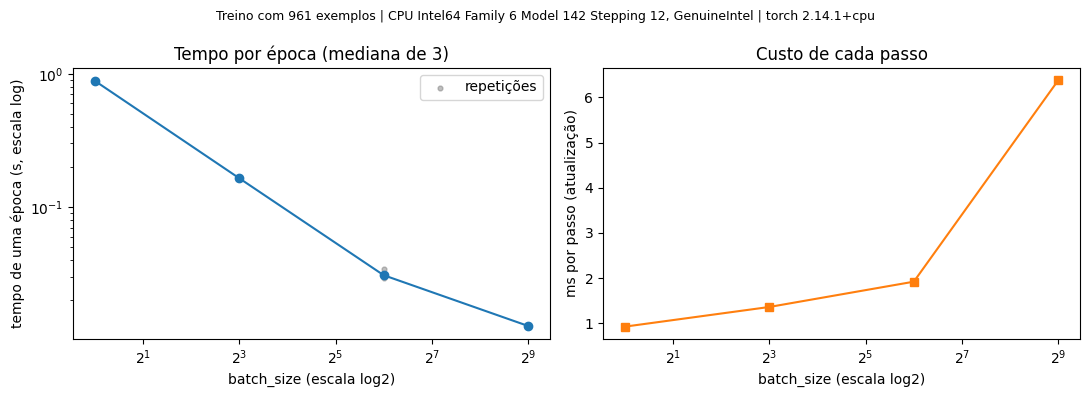

In [9]:
tamanhos_lote = [1, 8, 64, 512]
tempos = []

fixar_semente(SEED)
estado_inicial = copy.deepcopy(criar_modelo(11).state_dict())
criterio = nn.BCEWithLogitsLoss()

def uma_epoca_cronometrada(batch_size, medir=True):
    modelo = criar_modelo(11).to(DISPOSITIVO)
    modelo.load_state_dict(estado_inicial)              # sempre o mesmo ponto de partida
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)  # otimizador novo
    ld = DataLoader(ds_treino, batch_size=batch_size, shuffle=True, drop_last=False,
                    num_workers=0, generator=torch.Generator().manual_seed(SEED))
    t0 = time.perf_counter()
    treinar_epoca(modelo, ld, otimizador, criterio, DISPOSITIVO)
    return time.perf_counter() - t0, len(ld)

for bs in tamanhos_lote:
    uma_epoca_cronometrada(bs)  # aquecimento, descartado
    for rep in range(1, 4):
        seg, passos = uma_epoca_cronometrada(bs)
        tempos.append({'batch_size': bs, 'repeticao': rep, 'segundos': seg,
                       'passos': passos, 'exemplos': len(ds_treino)})

tab_tempos = pd.DataFrame(tempos)
resumo_a3 = (tab_tempos.pivot(index='batch_size', columns='repeticao', values='segundos')
             .add_prefix('rep_'))
resumo_a3['mediana_s'] = tab_tempos.groupby('batch_size').segundos.median()
resumo_a3['passos'] = tab_tempos.groupby('batch_size').passos.first()
resumo_a3['exemplos'] = len(ds_treino)
resumo_a3['ms_por_passo'] = 1000 * resumo_a3.mediana_s / resumo_a3.passos
resumo_a3['us_por_exemplo'] = 1e6 * resumo_a3.mediana_s / resumo_a3.exemplos
print(resumo_a3.round(4).to_string())
tab_tempos.to_csv(RESULTADOS / 'a3_tempos_brutos.csv', index=False)
resumo_a3.to_csv(RESULTADOS / 'a3_tempos_resumo.csv')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(resumo_a3.index, resumo_a3.mediana_s, 'o-')
ax[0].scatter(tab_tempos.batch_size, tab_tempos.segundos, s=12, alpha=0.5, color='gray', label='repetições')
ax[0].set_xscale('log', base=2); ax[0].set_yscale('log')
ax[0].set_xlabel('batch_size (escala log2)'); ax[0].set_ylabel('tempo de uma época (s, escala log)')
ax[0].set_title('Tempo por época (mediana de 3)'); ax[0].legend()
ax[1].plot(resumo_a3.index, resumo_a3.ms_por_passo, 's-', color='tab:orange')
ax[1].set_xscale('log', base=2)
ax[1].set_xlabel('batch_size (escala log2)'); ax[1].set_ylabel('ms por passo (atualização)')
ax[1].set_title('Custo de cada passo')
fig.suptitle(f'Treino com {len(ds_treino)} exemplos | CPU {platform.processor()} | torch {torch.__version__}', fontsize=9)
fig.tight_layout()
fig.savefig(RESULTADOS / 'a3_tempo_por_lote.png', dpi=120)
plt.show()

**Análise A3.** Medianas desta execução (CPU Intel Core i5-10210U, 4 threads do torch): **0,89 s** (lote 1, 961 passos), **0,16 s** (lote 8, 121 passos), **0,031 s** (lote 64, 16 passos) e **0,013 s** (lote 512, 2 passos). Os números exatos mudam um pouco de uma execução para outra (as repetições estão no gráfico e no CSV), mas a ordem se manteve.

O tempo cai bastante até 64: de 1 para 8 e de 8 para 64 a época fica uns 5x mais rápida a cada salto. De 64 para 512 o ganho foi bem menor (uns 2,4x), então é aí que eu vejo o retorno diminuindo. Isso faz sentido olhando o custo por passo: ele **sobe** com o lote (≈0,9 ms com 1 exemplo, ≈1,4 ms com 8, ≈1,9 ms com 64 e ≈6,4 ms com 512), só que muito menos do que proporcionalmente. Com lote pequeno quem domina é o custo fixo de cada passo (chamar o Python, montar o lote, zerar gradiente, rodar o Adam), e com lote grande começa a pesar a conta em si.

Cuidado na leitura: época mais rápida não quer dizer treino melhor. Com lote 1 a rede recebe 961 atualizações por época; com 512, só 2. Para chegar no mesmo ponto da perda o lote grande provavelmente precisaria de muito mais épocas (ou outra taxa de aprendizado), e isso eu não medi aqui. Esse item mede só custo de tempo, não convergência.

## A4. BatchNorm com último lote 1
Use um subconjunto de 65 observações do treino e lote 64, ou outra condição equivalente. Confirme o resto. Use `criar_modelo(11, batchnorm=True)`, modo de treino e `drop_last=False`. Capture especificamente o erro esperado, mostre sua mensagem e depois execute a correção que escolheu. Preserve as outras partes do notebook.

In [10]:
TAM_LOTE_BN = 64
n_sub = 65
sub_treino = particoes['treino'].sample(n=n_sub, random_state=SEED)  # só linhas do treino
print(f'Subconjunto: {n_sub} linhas | lote {TAM_LOTE_BN} | resto = {n_sub % TAM_LOTE_BN}')
assert n_sub % TAM_LOTE_BN == 1

# usa a normalização aprendida no treino principal
ds_bn = MeuDataset(sub_treino, FEATURES, ds_treino.media, ds_treino.desvio)

fixar_semente(SEED)
modelo_bn = criar_modelo(11, batchnorm=True)
otim_bn = torch.optim.Adam(modelo_bn.parameters(), lr=0.001)

# 1) reprodução do erro: drop_last=False deixa um último lote com 1 exemplo
ld_bn_errado = DataLoader(ds_bn, batch_size=TAM_LOTE_BN, shuffle=True, drop_last=False,
                          generator=torch.Generator().manual_seed(SEED))
print('Tamanhos dos lotes com drop_last=False:', [len(y) for _, y in ld_bn_errado])
try:
    treinar_epoca(modelo_bn, ld_bn_errado, otim_bn, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    print('Não deu erro (inesperado)')
except ValueError as erro:   # é o erro que o BatchNorm1d levanta em train() com 1 valor por canal
    print('Erro capturado (ValueError):', erro)

Subconjunto: 65 linhas | lote 64 | resto = 1
Tamanhos dos lotes com drop_last=False: [64, 1]
Erro capturado (ValueError): Expected more than 1 value per channel when training, got input size torch.Size([1, 16])


In [11]:
# 2) correção: drop_last=True no treino com BatchNorm.
# Recomeço do mesmo estado para a comparação ser justa.
fixar_semente(SEED)
modelo_bn = criar_modelo(11, batchnorm=True)
otim_bn = torch.optim.Adam(modelo_bn.parameters(), lr=0.001)
ld_bn_corrigido = DataLoader(ds_bn, batch_size=TAM_LOTE_BN, shuffle=True, drop_last=True,
                             generator=torch.Generator().manual_seed(SEED))
print('Tamanhos dos lotes com drop_last=True:', [len(y) for _, y in ld_bn_corrigido])
for ep in range(3):
    perda = treinar_epoca(modelo_bn, ld_bn_corrigido, otim_bn, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    print(f'época {ep + 1}: perda de treino {perda:.4f}  (rede continua em modo train: {modelo_bn.training})')

# quantas linhas diferentes chegaram a ser usadas em 20 épocas (o descartado muda porque há shuffle)
vistos = set()
for _ in range(20):
    for idx_lote in ld_bn_corrigido.batch_sampler:
        vistos.update(idx_lote)
print(f'Exemplos descartados por época: {n_sub - len(ld_bn_corrigido) * TAM_LOTE_BN} | '
      f'linhas distintas usadas em 20 épocas: {len(vistos)} de {n_sub}')

Tamanhos dos lotes com drop_last=True: [64]
época 1: perda de treino 0.6557  (rede continua em modo train: True)
época 2: perda de treino 0.6522  (rede continua em modo train: True)
época 3: perda de treino 0.6483  (rede continua em modo train: True)
Exemplos descartados por época: 1 | linhas distintas usadas em 20 épocas: 65 de 65


**Análise A4.** Com 65 linhas do treino e lote 64 o resto é 1, então o `DataLoader` com `drop_last=False` gera os lotes [64, 1]. No último lote o `BatchNorm1d` em modo `train()` não consegue calcular variância com um único valor por canal e levanta:

`ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 16])`

Capturei só `ValueError` e só nessa chamada, para não esconder outros erros do notebook.

**Correção escolhida:** `drop_last=True` no carregador de **treino**. A rede continua em `train()` e a BatchNorm continua usando estatísticas do lote, então o procedimento é o mesmo; só o lote incompleto deixa de existir. **Custo:** 1 observação de 65 (≈1,5%) fica de fora a cada época. Como o treino é embaralhado, quem fica de fora muda a cada época, e em 20 épocas as 65 linhas foram usadas pelo menos uma vez. Numa base pequena e com um lote que deixasse sobrar, por exemplo, 40 exemplos, o descarte seria bem maior, e aí eu preferiria mudar o tamanho do lote ou trocar BatchNorm por LayerNorm. Na avaliação não se descarta nada (lá a rede vai para `eval()` e usa as médias acumuladas, então lote 1 não é problema).

## C. Dois mecanismos de vazamento
Selecione duas formas; pelo menos uma entre 2/4/7 e uma com dados reais. Um caminho acessível é 1 e 2, usando a base incluída. **Formas 1–7 estão descritas no enunciado.**

Trabalhe apenas com as linhas principais de treino + validação. Crie partições internas `c_...`. Não use a partição principal de teste. Defina o modelo, a métrica e as condições antes de executar o par incorreto/corrigido. Se usar a forma 7, reserve desde o início os quatro conjuntos internos e compare seleções com orçamento igual.

Escolhi as formas **2 (alvo entre as características)** e **4 (duplicatas entre aprendizagem e avaliação)**, ambas com dados reais do Wine Quality.

Desenho comum, definido **antes** de rodar:
- **Dados:** só `particoes['treino']` + `particoes['validacao']` (chamo de `c_dev`). O teste principal não aparece nesta parte.
- **Partição interna:** `GroupShuffleSplit` 75/25 por `grupo_perfil` com semente 42 → `c_treino` e `c_aval`.
- **Modelo:** `RandomForestClassifier(n_estimators=200, random_state=42)` do scikit-learn. Usei floresta aleatória (e não a rede) porque é rápida, não precisa de normalização e consegue "decorar" exemplos, o que é justamente o comportamento que a forma 4 quer expor. Esse modelo é só desta parte.
- **Métrica principal:** acurácia em `c_aval`. Também mostro AUC-ROC como apoio, porque com 13% de positivos a acurácia sozinha é pouco sensível.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

resultados_c = []

c_dev = pd.concat([particoes['treino'], particoes['validacao']], ignore_index=True)
assert not set(c_dev.id_linha) & set(particoes['teste'].id_linha)  # teste principal fora

c_gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
c_idx_tr, c_idx_av = next(c_gss.split(c_dev, groups=c_dev.grupo_perfil))
c_treino, c_aval = c_dev.iloc[c_idx_tr], c_dev.iloc[c_idx_av]
print(f'c_dev: {len(c_dev)} linhas | c_treino: {len(c_treino)} | c_aval: {len(c_aval)} '
      f'| perfis em comum: {len(set(c_treino.grupo_perfil) & set(c_aval.grupo_perfil))}')

def c_modelo():
    return RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)

def c_avaliar(colunas, df_tr, df_av):
    m = c_modelo().fit(df_tr[colunas], df_tr.alvo)
    prob = m.predict_proba(df_av[colunas])[:, 1]
    return accuracy_score(df_av.alvo, (prob >= 0.5).astype(int)), roc_auc_score(df_av.alvo, prob), m

c_dev: 1279 linhas | c_treino: 961 | c_aval: 318 | perfis em comum: 0


### C — Forma 2: o alvo (ou algo derivado dele) entra como característica

**O que deveria estar protegido:** a nota sensorial `quality`. Ela é dada pelos provadores **depois** das medidas, e o alvo é calculado a partir dela. No uso real, quando o sistema precisa decidir se separa uma amostra, essa nota ainda não existe.

**Onde atravessa a fronteira:** na montagem da matriz de características. A versão incorreta usa `FEATURES + ['quality']`, ou seja, **12 colunas, sendo a 12ª exatamente a nota original sem nenhuma transformação**. Isso imita o erro comum de esquecer a coluna de origem do rótulo na tabela. A versão corrigida usa só as 11 medidas. O resto (partição, modelo, semente) é igual.

In [13]:
# ERRADO: 'quality' entra como característica (é a origem do alvo)
c_cols_errado = FEATURES + ['quality']
c_acc_f2_errado, c_auc_f2_errado, c_rf_errado = c_avaliar(c_cols_errado, c_treino, c_aval)

# CORRIGIDO: só as 11 medidas permitidas
c_acc_f2_certo, c_auc_f2_certo, c_rf_certo = c_avaliar(FEATURES, c_treino, c_aval)

print(f'Acurácia  incorreto: {c_acc_f2_errado:.4f} | corrigido: {c_acc_f2_certo:.4f} '
      f'| diferença: {100 * (c_acc_f2_errado - c_acc_f2_certo):+.2f} p.p.')
print(f'AUC-ROC   incorreto: {c_auc_f2_errado:.4f} | corrigido: {c_auc_f2_certo:.4f}')

importancias = pd.Series(c_rf_errado.feature_importances_, index=c_cols_errado).sort_values(ascending=False)
print('\nImportâncias no modelo incorreto (top 5):')
print(importancias.head().round(3).to_string())

resultados_c.append({'forma': 2, 'dados': 'Wine Quality real, c_dev (treino+val. da B2)',
                     'metrica': 'acurácia em c_aval', 'incorreto': c_acc_f2_errado,
                     'corrigido': c_acc_f2_certo,
                     'diferenca': 100 * (c_acc_f2_errado - c_acc_f2_certo), 'unidade': 'p.p.',
                     'informacao_indevida': 'coluna quality (origem do alvo) como 12ª entrada'})

Acurácia  incorreto: 1.0000 | corrigido: 0.8994 | diferença: +10.06 p.p.
AUC-ROC   incorreto: 1.0000 | corrigido: 0.8046

Importâncias no modelo incorreto (top 5):
quality             0.686
alcohol             0.096
sulphates           0.039
volatile acidity    0.035
density             0.033


**Análise da forma 2.** Com `quality` entre as entradas a floresta acerta **100%** da avaliação interna (AUC-ROC 1,000), contra **89,94%** (AUC-ROC 0,805) na versão correta: diferença de **+10,06 p.p.** de acurácia. A importância de `quality` no modelo incorreto é 0,69, bem acima de qualquer medida real, ou seja, o modelo basicamente aprendeu a regra `quality >= 7` e ignorou o resto.

A diferença em acurácia parece pequena para um vazamento tão grosseiro, mas é porque a acurácia correta já é alta por causa do desbalanceamento: 89,6% de `c_aval` é classe 0, então a versão correta (89,94%) quase empata com "chutar sempre 0". O teto de ganho era uns 10 p.p. e o modelo vazado pegou todo ele. A AUC mostra melhor o tamanho do problema: sai de 0,80 para um ordenamento perfeito. Esse resultado do incorreto não diz nada sobre como o modelo funcionaria na prática, porque no momento da decisão a nota não existe.

Uma observação: como usei a mesma semente e a mesma proporção (25% dos grupos) sobre os mesmos dados, `c_treino`/`c_aval` saíram com exatamente as mesmas linhas de treino/validação da B2. Não é problema para o experimento, porque tudo continua dentro do desenvolvimento e o teste principal não participa, mas é bom deixar registrado.

### C — Forma 4: duplicatas entre aprendizagem e avaliação

**O que deveria estar protegido:** perfis de medidas que o modelo não viu. A pergunta de uso é sobre amostras novas; se a mesma configuração das 11 medidas está no treino e na avaliação, o modelo pode acertar por memória.

**Onde atravessa a fronteira:** na partição. A versão incorreta divide `c_dev` **por linha** (`train_test_split` aleatório, 75/25), ignorando `grupo_perfil`. A versão corrigida divide **por grupo** (`GroupShuffleSplit` 75/25). Modelo, características (as 11) e proporções iguais.

**Problema da comparação:** para corrigir eu preciso mudar a partição, então o conjunto avaliado não é o mesmo nos dois casos e uma única semente pode refletir só sorte do sorteio. Por isso decidi **antes** de rodar repetir com 10 sementes fixas (0 a 9) e reportar todas, a média e o desvio. Também separo, dentro da avaliação incorreta, as linhas que têm "gêmeo" no treino das que não têm, porque é ali que o mecanismo aparece de fato.

In [14]:
from sklearn.model_selection import train_test_split

c_sementes = list(range(10))
c_linhas_f4 = []
for s in c_sementes:
    # ERRADO: divisão aleatória por linha -> perfis repetidos podem cair dos dois lados
    tr_e, av_e = train_test_split(c_dev, test_size=0.25, random_state=s)
    m_e = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(tr_e[FEATURES], tr_e.alvo)
    pred_e = m_e.predict(av_e[FEATURES])
    tem_gemeo = av_e.grupo_perfil.isin(tr_e.grupo_perfil).to_numpy()

    # CORRIGIDO: divisão por grupo de perfil
    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=s)
    i_tr, i_av = next(gss.split(c_dev, groups=c_dev.grupo_perfil))
    tr_c, av_c = c_dev.iloc[i_tr], c_dev.iloc[i_av]
    m_c = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(tr_c[FEATURES], tr_c.alvo)
    pred_c = m_c.predict(av_c[FEATURES])

    c_linhas_f4.append({
        'semente': s,
        'acc_incorreto': accuracy_score(av_e.alvo, pred_e),
        'acc_corrigido': accuracy_score(av_c.alvo, pred_c),
        'linhas_com_gemeo': int(tem_gemeo.sum()),
        'acc_com_gemeo': accuracy_score(av_e.alvo[tem_gemeo], pred_e[tem_gemeo]),
        'acc_sem_gemeo': accuracy_score(av_e.alvo[~tem_gemeo], pred_e[~tem_gemeo]),
        'prev_aval_incorreto': av_e.alvo.mean(), 'prev_aval_corrigido': av_c.alvo.mean(),
    })

c_tab_f4 = pd.DataFrame(c_linhas_f4)
c_tab_f4['dif_pp'] = 100 * (c_tab_f4.acc_incorreto - c_tab_f4.acc_corrigido)
print(c_tab_f4.round(4).to_string(index=False))
print('\nMédia (desvio) nas 10 sementes:')
for col in ['acc_incorreto', 'acc_corrigido', 'dif_pp', 'linhas_com_gemeo', 'acc_com_gemeo', 'acc_sem_gemeo']:
    print(f'  {col:>17}: {c_tab_f4[col].mean():.4f} ({c_tab_f4[col].std():.4f})')
print('Sementes em que o incorreto ficou acima do corrigido:', int((c_tab_f4.dif_pp > 0).sum()), 'de 10')
c_tab_f4.to_csv(RESULTADOS / 'c_forma4_sementes.csv', index=False)

resultados_c.append({'forma': 4, 'dados': 'Wine Quality real, c_dev (treino+val. da B2), 10 sementes',
                     'metrica': 'acurácia média na avaliação interna', 'incorreto': c_tab_f4.acc_incorreto.mean(),
                     'corrigido': c_tab_f4.acc_corrigido.mean(), 'diferenca': c_tab_f4.dif_pp.mean(),
                     'unidade': 'p.p. (média de 10)',
                     'informacao_indevida': 'perfis idênticos no treino e na avaliação'})

 semente  acc_incorreto  acc_corrigido  linhas_com_gemeo  acc_com_gemeo  acc_sem_gemeo  prev_aval_incorreto  prev_aval_corrigido  dif_pp
       0         0.9250         0.8770                72            1.0         0.9032               0.1125               0.1294  4.7977
       1         0.9062         0.8854                68            1.0         0.8810               0.1531               0.1465  2.0900
       2         0.8969         0.8638                67            1.0         0.8696               0.1406               0.1610  3.3098
       3         0.9000         0.8690                75            1.0         0.8694               0.1469               0.1374  3.0990
       4         0.9031         0.8865                53            1.0         0.8839               0.1375               0.1104  1.6622
       5         0.9125         0.8685                73            1.0         0.8866               0.1344               0.1254  4.3998
       6         0.9031         0.9148   

In [15]:
tabela_c = pd.DataFrame(resultados_c)
print(tabela_c.round(4).to_string(index=False))
tabela_c.to_csv(RESULTADOS / 'c_resumo.csv', index=False)

 forma                                                     dados                             metrica  incorreto  corrigido  diferenca            unidade                              informacao_indevida
     2              Wine Quality real, c_dev (treino+val. da B2)                  acurácia em c_aval     1.0000     0.8994    10.0629               p.p. coluna quality (origem do alvo) como 12ª entrada
     4 Wine Quality real, c_dev (treino+val. da B2), 10 sementes acurácia média na avaliação interna     0.9084     0.8791     2.9288 p.p. (média de 10)        perfis idênticos no treino e na avaliação


**Análise da forma 4.** Nas 10 sementes, a divisão por linha deu acurácia média de **90,84%** e a divisão por grupo **87,91%**, diferença média de **+2,93 p.p.** (desvio 1,93 p.p.). O incorreto ficou acima em 9 das 10 sementes.

O mecanismo aparece com clareza quando separo as linhas da avaliação incorreta: em média 69 das 320 linhas (≈22%) têm um gêmeo exato no treino, e nelas o modelo acertou **100%** em todas as sementes. Nas linhas sem gêmeo a acurácia foi 88,3%, praticamente igual à da divisão correta. Ou seja, o ganho do incorreto vem quase todo de memória, não de generalização. Ajuda o fato de que neste arquivo perfis iguais sempre têm o mesmo alvo.

Limites: como a correção muda a partição, os conjuntos avaliados não são os mesmos e as prevalências variam entre sorteios. A única semente com sinal invertido (6) é justamente uma em que a avaliação por grupo caiu com só 9,8% de positivos, o que deixa a acurácia mais fácil. Por isso não confio no valor de uma semente isolada e reporto a média; mesmo assim, 10 repetições é pouco para cravar o tamanho exato do efeito. Usei sementes 0 a 9 definidas antes, sem descartar nenhuma, e não dupliquei linhas para aumentar o efeito.

**Como preservei o teste principal:** os dois experimentos usam só `c_dev` (treino + validação da B2), há um `assert` garantindo que nenhum `id_linha` do teste está ali, e todas as variáveis começam com `c_`. O modelo da Parte C (floresta) não é reaproveitado na D.

## D7. Rede principal com parada antecipada
Construa uma rede nova; não reutilize os pesos ou estatísticas do experimento incorreto da Parte C. A arquitetura de apoio pode ser usada. Complete o laço: treinar, avaliar validação, comparar melhora, copiar o melhor estado, contar paciência, parar e restaurar. Use `copy.deepcopy(modelo.state_dict())` ou tensores clonados para guardar uma cópia independente.

Não forneça o loader de teste à função de treinamento. A perda de validação seleciona a época; o teste não aparece no histórico.

In [16]:
def treinar_com_parada(modelo, loader_treino, loader_validacao,
                       max_epocas=100, paciencia=10, min_delta=0.0001, lr=0.001):
    """Treina com parada antecipada monitorando a perda de VALIDAÇÃO.

    Considero melhora quando perda_val < melhor_perda - min_delta.
    Devolve um dicionário com histórico, melhor época, época final, melhor perda e
    o motivo da parada. Ao sair, o modelo está com os melhores pesos restaurados.
    """
    criterio = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = []
    melhor_perda = float('inf')
    melhor_epoca = 0
    melhor_estado = None
    sem_melhora = 0
    motivo = 'máximo de épocas'

    for epoca in range(1, max_epocas + 1):
        perda_tr = treinar_epoca(modelo, loader_treino, otimizador, criterio, DISPOSITIVO)
        perda_val = avaliar_perda(modelo, loader_validacao, criterio, DISPOSITIVO)  # sem gradiente
        historico.append({'epoca': epoca, 'perda_treino': perda_tr, 'perda_validacao': perda_val})

        if perda_val < melhor_perda - min_delta:
            melhor_perda = perda_val
            melhor_epoca = epoca
            melhor_estado = copy.deepcopy(modelo.state_dict())  # cópia independente
            sem_melhora = 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                motivo = f'paciência esgotada ({paciencia} épocas sem melhora)'
                break

    modelo.load_state_dict(melhor_estado)
    return {'historico': pd.DataFrame(historico), 'melhor_epoca': melhor_epoca,
            'epoca_final': epoca, 'melhor_perda': melhor_perda, 'motivo': motivo}

Configuração (fixada antes de treinar): rede de apoio 11 → 16 → ReLU → 1, sem BatchNorm, Adam lr=0,001, `BCEWithLogitsLoss` sem peso de classe, lote 64 com embaralhamento. Parada antecipada com as sugestões do enunciado: no máximo **100 épocas**, **paciência 10** e **melhora mínima 0,0001** na perda de validação.

O loader de teste não é passado para a função, então ele não tem como entrar no histórico.

Motivo da parada: paciência esgotada (10 épocas sem melhora)
Época final: 59 | melhor época: 49 | melhor perda de validação: 0.26523
 epoca  perda_treino  perda_validacao
    48       0.27047          0.26669
    49       0.26990          0.26523
    50       0.26926          0.26575
    51       0.26829          0.26603
    52       0.26758          0.26628
    53       0.26753          0.26580
    54       0.26684          0.26647
    55       0.26618          0.26692
    56       0.26598          0.26716
    57       0.26538          0.26797
    58       0.26440          0.26700
    59       0.26443          0.26574

Perda de validação do modelo restaurado: 0.26523
Perda registrada na melhor época:        0.26523
Perda na última época treinada:          0.26574


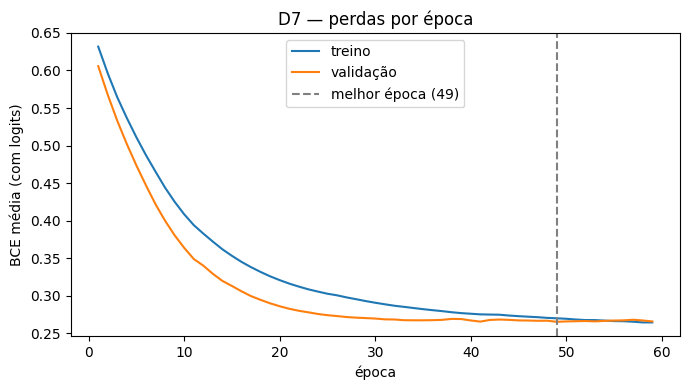

In [17]:
MAX_EPOCAS, PACIENCIA, MIN_DELTA = 100, 10, 0.0001

fixar_semente(SEED)
modelo_final = criar_modelo(11).to(DISPOSITIVO)
loader_treino = DataLoader(ds_treino, batch_size=64, shuffle=True, drop_last=False,
                           num_workers=0, generator=torch.Generator().manual_seed(SEED))
info_treino = treinar_com_parada(modelo_final, loader_treino, loader_validacao,
                                 max_epocas=MAX_EPOCAS, paciencia=PACIENCIA, min_delta=MIN_DELTA)
historico = info_treino['historico']
historico.to_csv(RESULTADOS / 'd7_historico.csv', index=False)

print('Motivo da parada:', info_treino['motivo'])
print('Época final:', info_treino['epoca_final'], '| melhor época:', info_treino['melhor_epoca'],
      '| melhor perda de validação:', round(info_treino['melhor_perda'], 5))
print(historico.tail(12).round(5).to_string(index=False))

# confirmação da restauração: recalculo a perda de validação com o modelo restaurado
perda_restaurada = avaliar_perda(modelo_final, loader_validacao, nn.BCEWithLogitsLoss(), DISPOSITIVO)
perda_ultima = historico.perda_validacao.iloc[-1]
print(f'\nPerda de validação do modelo restaurado: {perda_restaurada:.5f}')
print(f'Perda registrada na melhor época:        {info_treino["melhor_perda"]:.5f}')
print(f'Perda na última época treinada:          {perda_ultima:.5f}')
assert abs(perda_restaurada - info_treino['melhor_perda']) < 1e-6

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historico.epoca, historico.perda_treino, label='treino')
ax.plot(historico.epoca, historico.perda_validacao, label='validação')
ax.axvline(info_treino['melhor_epoca'], color='gray', ls='--', label=f'melhor época ({info_treino["melhor_epoca"]})')
ax.set_xlabel('época'); ax.set_ylabel('BCE média (com logits)')
ax.set_title('D7 — perdas por época'); ax.legend()
fig.tight_layout(); fig.savefig(RESULTADOS / 'd7_curvas_perda.png', dpi=120)
plt.show()

**Análise D7.** A paciência disparou: a melhor perda de validação foi **0,26523 na época 49**, depois foram 10 épocas sem melhora maior que 0,0001 e o treino parou na **época 59** (antes do limite de 100). Restaurei o estado salvo da época 49 e conferi recalculando a perda de validação com o modelo restaurado: deu 0,26523, igual à registrada, enquanto a última época tinha 0,26574.

Nas curvas a perda de validação fica um pouco abaixo da de treino em quase todo o treinamento. Acho que isso tem duas explicações: a perda de treino é a média durante a época, com os pesos ainda mudando, e a validação tem menos positivos (10,4%) do que o treino (14,5%), o que deixa ela "mais fácil" para uma BCE. A partir da época ~30 as duas curvas quase não se mexem, então não aparece um overfitting forte; a parada só cortou épocas que não estavam ajudando.

## D4. Custos como hipóteses explícitas
Descreva a ação de selecionar uma amostra como alta nota. Defina custos positivos de falso positivo e falso negativo, uma unidade e uma justificativa. Não existem custos reais no CSV. Acertos custam zero na simplificação deste laboratório.

**Decisão:** prever positivo = mandar a amostra para a análise especial de alta nota. Prever negativo = a amostra segue o fluxo normal e não é analisada.

- **Falso positivo (FP):** uma amostra com nota < 7 é mandada para a análise especial. Custo: uma análise gasta à toa (tempo de laboratório/provadores). **C_FP = 1 unidade de esforço.**
- **Falso negativo (FN):** uma amostra com nota >= 7 não é selecionada. A análise especial existe justamente para achar essas amostras, que são poucas (~13%), então perder uma é pior do que gastar uma análise. **C_FN = 3 unidades de esforço.**
- Acertos custam 0 (simplificação do laboratório).

**Importante:** esses valores são **hipóteses minhas** para o exercício. O CSV não tem preço, custo de análise nem valor de venda de nenhum vinho. O que importa é a relação: estou dizendo que deixar passar um bom vinho "vale" o mesmo que três análises desperdiçadas. Se a análise fosse muito cara (ou o vinho bom pouco valioso), a razão mudaria e o limiar também.

In [18]:
C_FP = 1.0  # unidade de esforço: uma análise especial desperdiçada (hipotético)
C_FN = 3.0  # deixar de selecionar uma amostra de nota >= 7 (hipotético, 3x pior que um FP)
print(f'C_FP = {C_FP}, C_FN = {C_FN} (unidades de esforço hipotéticas)')

C_FP = 1.0, C_FN = 3.0 (unidades de esforço hipotéticas)


## D5 e D6. Escolha na validação e fórmula
Use `obter_escores(modelo_final, loader_validacao, DISPOSITIVO)` após a restauração. Compare limiares usando os rótulos da validação. Inclua os casos extremos; registre regra de empate ou resolução de uma grade. Compare com 0,5 e com `C_FP/(C_FP+C_FN)`. Investigue calibração sem transformar sigmoide em garantia de probabilidade.

Salve modelo, normalização, lista de entradas, custos e limiar como escolhas fixadas antes da próxima seção.

Como faço a busca:
- candidatos = todos os **escores únicos** da validação, mais `0.0` (tudo positivo) e `inf` (tudo negativo). Não é grade, então não tem aproximação de resolução;
- regra: positivo se `escore >= limiar`;
- custo = `C_FP·FP + C_FN·FN`;
- **desempate:** entre limiares com o mesmo custo mínimo fico com o **maior** limiar, porque ele seleciona menos amostras (menos análises) para o mesmo custo.

274 limiares avaliados na validação (318 observações, 33 positivas)


Limiares empatados no custo mínimo: 1
                   regra  limiar  TN  FP  FN  TP  positivos_previstos  custo  custo_medio
                     0,5  0.5000 273  12  25   8                   20   87.0       0.2736
  escolhido na validação  0.2766 252  33   9  24                   57   60.0       0.1887
fórmula C_FP/(C_FP+C_FN)  0.2500 250  35   9  24                   59   62.0       0.1950


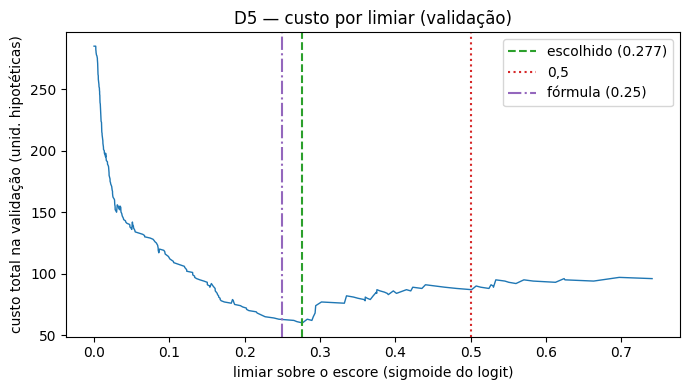

In [19]:
from sklearn.metrics import confusion_matrix, brier_score_loss
from sklearn.calibration import calibration_curve

def custo_no_limiar(y, escores, limiar):
    pred = (escores >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'limiar': limiar, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'positivos_previstos': fp + tp, 'custo': C_FP * fp + C_FN * fn}

y_val, s_val = obter_escores(modelo_final, loader_validacao, DISPOSITIVO)
assert np.array_equal(y_val, particoes['validacao'].alvo.to_numpy())  # alinhamento conferido

candidatos = np.concatenate([[0.0], np.unique(s_val), [np.inf]])
busca = pd.DataFrame([custo_no_limiar(y_val, s_val, l) for l in candidatos])
custo_min = busca.custo.min()
limiar_escolhido = float(busca.loc[busca.custo == custo_min, 'limiar'].max())  # desempate: maior limiar

linha_05 = custo_no_limiar(y_val, s_val, 0.5)
linha_esc = custo_no_limiar(y_val, s_val, limiar_escolhido)
limiar_formula = C_FP / (C_FP + C_FN)
linha_formula = custo_no_limiar(y_val, s_val, limiar_formula)

print(f'{len(candidatos)} limiares avaliados na validação ({len(y_val)} observações, {y_val.sum()} positivas)')
print(f'Limiares empatados no custo mínimo: {(busca.custo == custo_min).sum()}')
comp = pd.DataFrame([dict(regra='0,5', **linha_05),
                     dict(regra='escolhido na validação', **linha_esc),
                     dict(regra='fórmula C_FP/(C_FP+C_FN)', **linha_formula)])
comp['custo_medio'] = comp.custo / len(y_val)
print(comp.round(4).to_string(index=False))
comp.to_csv(RESULTADOS / 'd5_comparacao_validacao.csv', index=False)
busca.to_csv(RESULTADOS / 'd5_busca_limiar_validacao.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
b = busca[np.isfinite(busca.limiar)]
ax.plot(b.limiar, b.custo, lw=1)
ax.axvline(limiar_escolhido, color='tab:green', ls='--', label=f'escolhido ({limiar_escolhido:.3f})')
ax.axvline(0.5, color='tab:red', ls=':', label='0,5')
ax.axvline(limiar_formula, color='tab:purple', ls='-.', label=f'fórmula ({limiar_formula:.2f})')
ax.set_xlabel('limiar sobre o escore (sigmoide do logit)'); ax.set_ylabel('custo total na validação (unid. hipotéticas)')
ax.set_title('D5 — custo por limiar (validação)'); ax.legend()
fig.tight_layout(); fig.savefig(RESULTADOS / 'd5_custo_por_limiar.png', dpi=120)
plt.show()

Brier da rede na validação: 0.0790 | Brier prevendo sempre a prevalência do treino: 0.0947
Escore médio na validação: 0.1269 | proporção positiva real: 0.1038
 escore_medio_no_bin  fracao_positiva_real
               0.005                 0.000
               0.009                 0.000
               0.018                 0.026
               0.031                 0.075
               0.068                 0.075
               0.138                 0.026
               0.255                 0.250
               0.490                 0.375


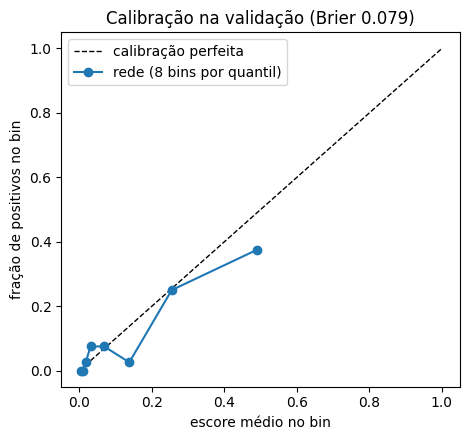

In [20]:
# D6: os escores parecem probabilidades? Brier e diagrama de calibração na validação
brier = brier_score_loss(y_val, s_val)
brier_ref = brier_score_loss(y_val, np.full_like(s_val, ds_treino.y.mean().item()))
print(f'Brier da rede na validação: {brier:.4f} | Brier prevendo sempre a prevalência do treino: {brier_ref:.4f}')
print(f'Escore médio na validação: {s_val.mean():.4f} | proporção positiva real: {y_val.mean():.4f}')

frac_pos, media_prev = calibration_curve(y_val, s_val, n_bins=8, strategy='quantile')
print(pd.DataFrame({'escore_medio_no_bin': media_prev, 'fracao_positiva_real': frac_pos}).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='calibração perfeita')
ax.plot(media_prev, frac_pos, 'o-', label='rede (8 bins por quantil)')
ax.set_xlabel('escore médio no bin'); ax.set_ylabel('fração de positivos no bin')
ax.set_title(f'Calibração na validação (Brier {brier:.3f})'); ax.legend()
fig.tight_layout(); fig.savefig(RESULTADOS / 'd6_calibracao_validacao.png', dpi=120)
plt.show()

**Análise D5/D6.** Avaliei 274 limiares na validação (todos os escores únicos mais os dois extremos), sem grade. O menor custo foi **60 unidades** no limiar **0,2766** (não houve empate), contra **87** no limiar 0,5. Em custo médio: 0,189 contra 0,274 por observação. O limiar escolhido seleciona muito mais amostras (57 em vez de 20) e com isso cai de 25 para 9 falsos negativos, aceitando 33 falsos positivos em vez de 12. Com C_FN = 3·C_FP essa troca compensa.

A fórmula dá C_FP/(C_FP+C_FN) = 1/4 = **0,25**. Na validação o custo em 0,25 seria 62, só 2 falsos positivos a mais que o escolhido, então a busca e a fórmula chegam em lugares bem próximos. Mesmo assim, eu não diria que isso prova calibração:
- o Brier da rede (0,079) é melhor que prever sempre a prevalência (0,095), então os escores carregam informação, mas o diagrama mostra o bin mais alto com escore médio 0,49 e só 37,5% de positivos (a rede superestima no topo);
- o escore médio na validação (0,127) é maior que a proporção real (0,104). Parte disso é que a rede aprendeu a prevalência do treino (14,5%) e a validação tem menos positivos;
- são só 33 positivos e ~40 linhas por bin, então tanto o diagrama quanto o ponto exato do mínimo são ruidosos. O custo é uma escada, e qualquer limiar entre dois escores vizinhos dá a mesma decisão.

Não usei peso de classe nem reamostragem, então essas fontes de distorção não se aplicam aqui. Também vale lembrar que a mesma validação foi usada para parar o treino e para escolher o limiar, então esses números de validação são de desenvolvimento e tendem a ser otimistas. A estimativa que vale é a do teste, abaixo.

In [21]:
# Congelando tudo antes de abrir o teste
decisao = {
    'modelo': 'criar_modelo(11), melhor época %d restaurada' % info_treino['melhor_epoca'],
    'entradas': FEATURES,
    'media_treino': ds_treino.media.tolist(),
    'desvio_treino_ddof0': ds_treino.desvio.tolist(),
    'C_FP': C_FP, 'C_FN': C_FN,
    'limiar_escolhido': limiar_escolhido,
    'regra': 'positivo se escore >= limiar; empate -> maior limiar',
}
torch.save(modelo_final.state_dict(), RESULTADOS / 'd_modelo_final.pt')
import json
(RESULTADOS / 'd_decisao_congelada.json').write_text(json.dumps(decisao, indent=2, ensure_ascii=False), encoding='utf-8')
decisao_congelada = True
print('Decisão congelada. Limiar =', round(limiar_escolhido, 4))

Decisão congelada. Limiar = 0.2766


## D1, D2 e D3. Avaliação final
Só agora obtenha escores no teste com o modelo restaurado e decisão congelada. Avalie as duas regras já fixadas (0,5 e limiar escolhido). O baseline usa a classe majoritária **do treino**. Produza matriz com ordem `[0, 1]`, métricas, prevalência e custos.

AUC-ROC e AUC-PR usam escores. Com `precision_recall_curve`, calcule a área trapezoidal usando `auc(recall, precision)`; se reportar `average_precision_score`, chame-a AP. Na ROC, desenhe a diagonal aleatória. Na PR, desenhe a prevalência do teste.

Não use o resultado do teste para voltar à busca. Relate os limites observados.

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, precision_recall_curve, auc, average_precision_score

avaliacao_final = None
if not decisao_congelada:
    print('Avaliação final pendente: concluir o desenvolvimento e congelar a decisão.')
else:
    # escores do teste: uma vez só
    y_teste, s_teste = obter_escores(modelo_final, loader_teste, DISPOSITIVO)
    assert np.array_equal(y_teste, particoes['teste'].alvo.to_numpy())
    prev_teste = y_teste.mean()

    auc_roc = roc_auc_score(y_teste, s_teste)
    prec_c, rev_c, _ = precision_recall_curve(y_teste, s_teste)
    auc_pr = auc(rev_c, prec_c)           # área trapezoidal
    ap = average_precision_score(y_teste, s_teste)  # AP, reportada à parte

    classe_majoritaria = int(particoes['treino'].alvo.mode()[0])
    print(f'Teste: {len(y_teste)} observações, {y_teste.sum()} positivas (proporção {prev_teste:.4f})')
    print('Classe majoritária no treino:', classe_majoritaria)

    def linha_metricas(nome, limiar, pred, com_auc=True):
        tn, fp, fn, tp = confusion_matrix(y_teste, pred, labels=[0, 1]).ravel()
        return {'regra': nome, 'limiar': limiar,
                'acuracia': accuracy_score(y_teste, pred),
                'precisao': precision_score(y_teste, pred, zero_division=0),
                'revocacao': recall_score(y_teste, pred, zero_division=0),
                'F1': f1_score(y_teste, pred, zero_division=0),
                'AUC-ROC': auc_roc if com_auc else np.nan,
                'AUC-PR (trap.)': auc_pr if com_auc else np.nan,
                'AP': ap if com_auc else np.nan,
                'FP': fp, 'FN': fn, 'custo_total': C_FP * fp + C_FN * fn,
                'custo_por_obs': (C_FP * fp + C_FN * fn) / len(y_teste)}

    pred_trivial = np.full_like(y_teste, classe_majoritaria)
    pred_05 = (s_teste >= 0.5).astype(int)
    pred_esc = (s_teste >= limiar_escolhido).astype(int)

    avaliacao_final = pd.DataFrame([
        linha_metricas('Trivial do treino (sempre %d)' % classe_majoritaria, 'não se aplica', pred_trivial, com_auc=False),
        linha_metricas('Rede: padrão', 0.5, pred_05),
        linha_metricas('Rede: escolhido na validação', round(limiar_escolhido, 4), pred_esc),
    ])
    print(avaliacao_final.round(4).to_string(index=False))
    avaliacao_final.to_csv(RESULTADOS / 'd2_tabela_final_teste.csv', index=False)

    for nome, pred in [('limiar 0,5', pred_05), (f'limiar {limiar_escolhido:.3f}', pred_esc), ('trivial', pred_trivial)]:
        cm = confusion_matrix(y_teste, pred, labels=[0, 1])
        print(f'\nMatriz de confusão ({nome}) — linhas = real, colunas = previsto, ordem [0, 1]')
        print(pd.DataFrame(cm, index=['real 0', 'real 1'], columns=['prev 0', 'prev 1']).to_string())

Teste: 320 observações, 45 positivas (proporção 0.1406)
Classe majoritária no treino: 0
                       regra        limiar  acuracia  precisao  revocacao    F1  AUC-ROC  AUC-PR (trap.)     AP  FP  FN  custo_total  custo_por_obs
Trivial do treino (sempre 0) não se aplica    0.8594    0.0000     0.0000 0.000      NaN             NaN    NaN   0  45        135.0         0.4219
                Rede: padrão           0.5    0.8781    0.6667     0.2667 0.381   0.8906          0.5641 0.5736   6  33        105.0         0.3281
Rede: escolhido na validação        0.2766    0.8562    0.4912     0.6222 0.549   0.8906          0.5641 0.5736  29  17         80.0         0.2500

Matriz de confusão (limiar 0,5) — linhas = real, colunas = previsto, ordem [0, 1]
        prev 0  prev 1
real 0     269       6
real 1      33      12

Matriz de confusão (limiar 0.277) — linhas = real, colunas = previsto, ordem [0, 1]
        prev 0  prev 1
real 0     246      29
real 1      17      28

Matriz de con

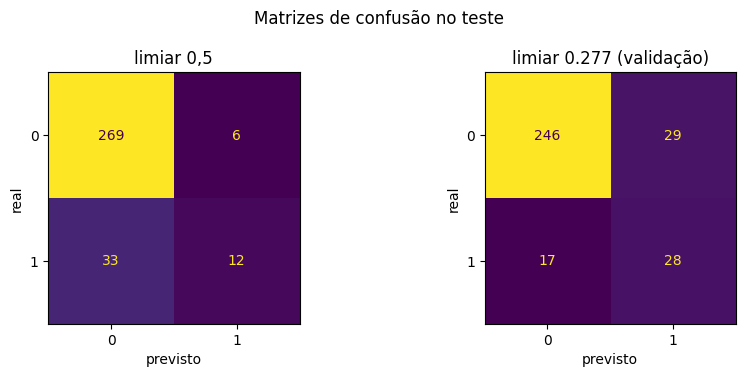

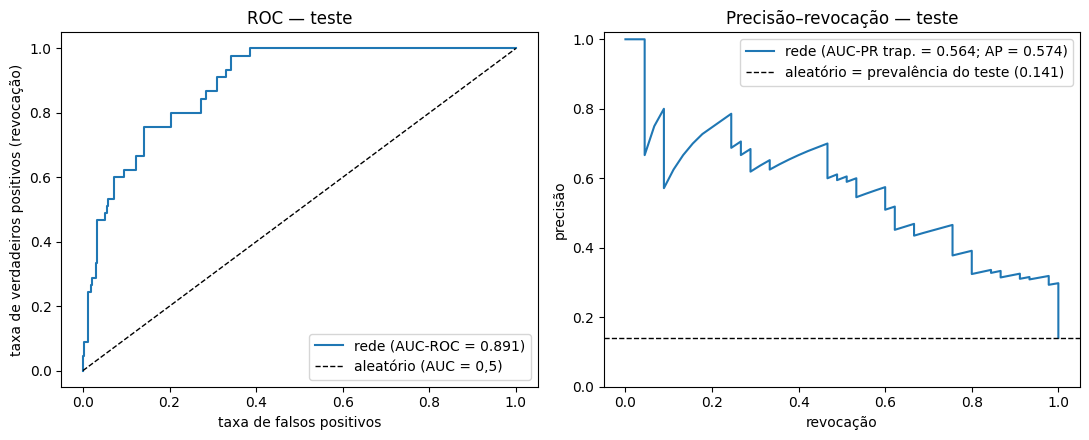

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

if avaliacao_final is not None:
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
    for a, (nome, pred) in zip(ax, [('limiar 0,5', pred_05), (f'limiar {limiar_escolhido:.3f} (validação)', pred_esc)]):
        ConfusionMatrixDisplay(confusion_matrix(y_teste, pred, labels=[0, 1]), display_labels=[0, 1]).plot(ax=a, colorbar=False)
        a.set_title(nome); a.set_xlabel('previsto'); a.set_ylabel('real')
    fig.suptitle('Matrizes de confusão no teste')
    fig.tight_layout(); fig.savefig(RESULTADOS / 'd2_matrizes_confusao.png', dpi=120)
    plt.show()

    # D3: ROC e PR lado a lado
    fpr, tpr, _ = roc_curve(y_teste, s_teste)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].plot(fpr, tpr, label=f'rede (AUC-ROC = {auc_roc:.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='aleatório (AUC = 0,5)')
    ax[0].set_xlabel('taxa de falsos positivos'); ax[0].set_ylabel('taxa de verdadeiros positivos (revocação)')
    ax[0].set_title('ROC — teste'); ax[0].legend(loc='lower right')
    ax[1].plot(rev_c, prec_c, label=f'rede (AUC-PR trap. = {auc_pr:.3f}; AP = {ap:.3f})')
    ax[1].axhline(prev_teste, color='k', ls='--', lw=1, label=f'aleatório = prevalência do teste ({prev_teste:.3f})')
    ax[1].set_xlabel('revocação'); ax[1].set_ylabel('precisão')
    ax[1].set_title('Precisão–revocação — teste'); ax[1].legend(loc='upper right')
    ax[1].set_ylim(0, 1.02)
    fig.tight_layout(); fig.savefig(RESULTADOS / 'd3_roc_pr_teste.png', dpi=120)
    plt.show()

**Análise D1–D3.** O teste tem 320 observações e 45 positivas (**14,1%**). A classe majoritária no treino é 0, então o classificador trivial sempre diz "não seleciona": acerta **85,9%** mas não encontra nenhum vinho bom (revocação 0) e custa 135 unidades (0,42 por observação). Para ele, precisão e F1 aparecem como 0 por convenção (`zero_division=0`, já que não há nenhuma previsão positiva), e as AUCs **não são reportadas**, porque um escore constante não gera curva.

A rede com 0,5 tem a maior acurácia (**87,8%**), só 1,9 p.p. acima do trivial, e acha apenas 12 dos 45 positivos (revocação 26,7%). Com o limiar fixado na validação (0,2766) a acurácia **cai** para 85,6% (abaixo do trivial!), mas a revocação sobe para **62,2%** (28 de 45), o F1 vai de 0,38 para 0,55 e o custo total cai de 105 para **80** (0,25 por observação). Isso é exatamente o que os custos pediam: aceitar mais falsos positivos (29 contra 6) para perder menos vinhos bons (17 contra 33 FN). É um bom exemplo de que a acurácia sozinha aponta para a regra errada quando as classes são desbalanceadas e os erros têm pesos diferentes.

As AUCs são as mesmas nas duas linhas porque os escores são os mesmos: **AUC-ROC 0,891**, **AUC-PR trapezoidal 0,564** e **AP 0,574** (reportada separada, porque não é a mesma área). A AUC-PR é bem mais baixa que a ROC, mas está muito acima da linha de referência da PR (0,141, a prevalência do teste), que é a comparação justa nesse gráfico.

Na ordem do relatório, o custo do limiar escolhido no teste (0,25/obs) ficou acima do que se via na validação (0,19/obs), o que é esperado já que a validação foi usada para escolher. O teste foi aberto uma vez, depois de congelar modelo, normalização, custos e limiar, e não voltei a nenhuma escolha depois de ver esses números.

## D8. Recomendação final
Escreva no README o parágrafo para quem decide: ação, limiar, evidência final, custos hipotéticos, riscos e limitações. Cite o conjunto avaliado. Não reivindique desempenho em novos produtores, regiões ou datas não observados.

## Conferência da entrega
Reinicie o kernel e execute tudo. O notebook preenchido deve mostrar as saídas de todas as partes; pendências não são resultados. Preencha o README e o arquivo obrigatório de uso de IA. Inclua as referências e registre alterações no apoio.

**D8 — Recomendação.** O modelo pode apoiar a **triagem** de quais amostras de vinho tinto mandar para a análise especial de alta nota (quality >= 7), a partir das 11 medidas físico-químicas. Recomendo o limiar **0,2766**, fixado na validação com custos **hipotéticos** de 1 unidade por análise desperdiçada (FP) e 3 por vinho bom não selecionado (FN). No teste reservado (320 amostras, 14,1% positivas), essa regra encontrou 28 dos 45 vinhos bons (revocação 62%), com precisão de 49% (cerca de metade das amostras enviadas são realmente de alta nota) e custo de 0,25 unidade por amostra, contra 0,33 no limiar 0,5 e 0,42 sem modelo nenhum. O erro que mais merece atenção ainda é o falso negativo: 17 vinhos bons (38%) passariam despercebidos; se a análise for barata, vale baixar o limiar e aceitar mais envios. Limitações: os custos são suposições minhas e não números da operação; o resultado vale para esta base (vinhos tintos portugueses do estudo de Cortez et al.), sem datas, produtores ou regiões, então não garante o mesmo desempenho em outras safras, outros produtores ou vinho branco; a validação tem poucos positivos (33), o que deixa o limiar instável; e os escores da rede não estão bem calibrados no topo, então não devem ser lidos como probabilidade de o vinho ser bom.

In [24]:
pendencias = []
for nome, valor in [('particoes', particoes), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_escolhido), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)
print('Esta checagem não corrige a análise nem substitui o checklist do enunciado.')

Pendências estruturais: []
Esta checagem não corrige a análise nem substitui o checklist do enunciado.
